# ============================================================
# PROJECT: Earthquakes in Indonesia
# PURPOSE: Exploratory data analysis and visualization
# ENVIRONMENT: Google Colab
# ============================================================

In [1]:
# 1. INSTALLATION (run only if PySpark is not installed)
# !pip install pyspark

In [1]:
# 2. IMPORT LIBRARIES
import psutil
import pyspark
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, to_date, coalesce, count, min as spark_min,
    max as spark_max, sum as spark_sum, trunc, sequence, explode
)

In [3]:
# 3. INITIALIZE SPARK AND LOAD DATA
csv_file = "..\data\katalog_gempa.csv"

spark = (
    SparkSession.builder
    .appName("Earthquakes In Indonesia")
    .getOrCreate()
)

df = spark.read.csv(csv_file, header=True, inferSchema=True)

print("=== DATA SCHEMA ===")
df.printSchema()

print("=== SAMPLE DATA ===")
df.show(20, truncate=False)

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
C:\Users\ACER\AppData\Local\Temp\ipykernel_34340\3363133448.py:2: SyntaxWarning: invalid escape sequence '\d'
  csv_file = "..\data\katalog_gempa.csv"


=== DATA SCHEMA ===
root
 |-- tgl: string (nullable = true)
 |-- ot: timestamp (nullable = true)
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- depth: integer (nullable = true)
 |-- mag: double (nullable = true)
 |-- remark: string (nullable = true)
 |-- strike1: double (nullable = true)
 |-- dip1: double (nullable = true)
 |-- rake1: double (nullable = true)
 |-- strike2: double (nullable = true)
 |-- dip2: double (nullable = true)
 |-- rake2: double (nullable = true)

=== SAMPLE DATA ===
+----------+-----------------------+-----+------+-----+---+----------------------------+-------+----+-----+-------+----+-----+
|tgl       |ot                     |lat  |lon   |depth|mag|remark                      |strike1|dip1|rake1|strike2|dip2|rake2|
+----------+-----------------------+-----+------+-----+---+----------------------------+-------+----+-----+-------+----+-----+
|2008/11/01|2026-10-21 21:02:43.058|-9.18|119.06|10   |4.9|Sumba Region - Indonesia    |NULL   |

In [4]:
# 4. SELECT RELEVANT COLUMNS AND EXPLORE DATA
selected_cols = ["tgl", "ot", "lat", "lon", "depth", "mag", "remark"]
df_selected = df.select(*selected_cols)

print("=== SELECTED DATA ===")
df_selected.show(20, truncate=False)

print("=== DESCRIPTIVE SUMMARY ===")
df_selected.summary().show(truncate=False)

# Create a temporary SQL view
df_selected.createOrReplaceTempView("EarthquakesData")


=== SELECTED DATA ===
+----------+-----------------------+-----+------+-----+---+----------------------------+
|tgl       |ot                     |lat  |lon   |depth|mag|remark                      |
+----------+-----------------------+-----+------+-----+---+----------------------------+
|2008/11/01|2026-10-21 21:02:43.058|-9.18|119.06|10   |4.9|Sumba Region - Indonesia    |
|2008/11/01|2026-10-21 20:58:50.248|-6.55|129.64|10   |4.6|Banda Sea                   |
|2008/11/01|2026-10-21 17:43:12.941|-7.01|106.63|121  |3.7|Java - Indonesia            |
|2008/11/01|2026-10-21 16:24:14.755|-3.3 |127.85|10   |3.2|Seram - Indonesia           |
|2008/11/01|2026-10-21 16:20:37.327|-6.41|129.54|70   |4.3|Banda Sea                   |
|2008/11/01|2026-10-21 14:47:00.029|-7.37|105.31|18   |3.3|Java - Indonesia            |
|2008/11/01|2026-10-21 13:04:38.742|0.1  |98.55 |12   |4.7|Northern Sumatra - Indonesia|
|2008/11/01|2026-10-21 10:23:51.646|-7.07|129.67|135  |4.8|Banda Sea                   |

In [5]:
# 5. DATA ANALYSIS: MAGNITUDE FREQUENCY

# 5.1 Most frequently recorded magnitude in the full dataset
query_most_frequent = """
SELECT mag, COUNT(*) AS jumlah_data
FROM EarthquakesData
WHERE mag IS NOT NULL
GROUP BY mag
ORDER BY jumlah_data DESC
LIMIT 1
"""
print("=== MOST FREQUENT MAGNITUDE: ALL DATA ===")
spark.sql(query_most_frequent).show()

=== MOST FREQUENT MAGNITUDE: ALL DATA ===
+---+-----------+
|mag|jumlah_data|
+---+-----------+
|3.3|       4530|
+---+-----------+



In [6]:
# 5.2 Least frequently recorded magnitude in the full dataset
query_least_frequent = """
SELECT mag, COUNT(*) AS jumlah_data
FROM EarthquakesData
WHERE mag IS NOT NULL
GROUP BY mag
ORDER BY jumlah_data ASC
LIMIT 1
"""
print("=== LEAST FREQUENT MAGNITUDE: ALL DATA ===")
spark.sql(query_least_frequent).show()

=== LEAST FREQUENT MAGNITUDE: ALL DATA ===
+---+-----------+
|mag|jumlah_data|
+---+-----------+
|7.9|          1|
+---+-----------+



In [7]:
# 5.3 Most frequently recorded magnitude in Sumbawa Region
query_sumbawa_most_frequent = """
SELECT mag, COUNT(*) AS jumlah_data
FROM EarthquakesData
WHERE remark LIKE '%Sumbawa Region%' AND mag IS NOT NULL
GROUP BY mag
ORDER BY jumlah_data DESC
LIMIT 1
"""
print("=== MOST FREQUENT MAGNITUDE: SUMBAWA REGION ===")
spark.sql(query_sumbawa_most_frequent).show()


=== MOST FREQUENT MAGNITUDE: SUMBAWA REGION ===
+---+-----------+
|mag|jumlah_data|
+---+-----------+
|2.7|        445|
+---+-----------+



In [8]:
# 5.4 Least frequently recorded magnitude in Sumbawa Region
query_sumbawa_least_frequent = """
SELECT mag, COUNT(*) AS jumlah_data
FROM EarthquakesData
WHERE remark LIKE '%Sumbawa Region%' AND mag IS NOT NULL
GROUP BY mag
ORDER BY jumlah_data ASC
LIMIT 1
"""
print("=== LEAST FREQUENT MAGNITUDE: SUMBAWA REGION ===")
spark.sql(query_sumbawa_least_frequent).show()

=== LEAST FREQUENT MAGNITUDE: SUMBAWA REGION ===
+---+-----------+
|mag|jumlah_data|
+---+-----------+
|7.0|          1|
+---+-----------+



In [9]:
# 5.5 Sumbawa magnitude counts at or above 5.0
query_sumbawa_mag_ge_5 = """
SELECT mag, COUNT(*) AS jumlah_gempa
FROM EarthquakesData
WHERE remark LIKE '%Sumbawa Region%' AND mag >= 5.0
GROUP BY mag
ORDER BY mag ASC
"""
print("=== SUMBAWA MAGNITUDE >= 5.0 ===")
spark.sql(query_sumbawa_mag_ge_5).show(100, truncate=False)

=== SUMBAWA MAGNITUDE >= 5.0 ===
+---+------------+
|mag|jumlah_gempa|
+---+------------+
|5.0|37          |
|5.1|30          |
|5.2|27          |
|5.3|7           |
|5.4|10          |
|5.5|6           |
|5.6|5           |
|5.7|2           |
|5.8|2           |
|6.2|4           |
|6.3|1           |
|6.4|2           |
|6.5|2           |
|6.7|1           |
|6.8|2           |
|6.9|2           |
|7.0|1           |
+---+------------+



In [10]:
# 5.6 Sumbawa magnitude counts at or below 5.0
query_sumbawa_mag_le_5 = """
SELECT mag, COUNT(*) AS jumlah_gempa
FROM EarthquakesData
WHERE remark LIKE '%Sumbawa Region%' AND mag <= 5.0
GROUP BY mag
ORDER BY mag ASC
"""
print("=== SUMBAWA MAGNITUDE <= 5.0 ===")
spark.sql(query_sumbawa_mag_le_5).show(100, truncate=False)

=== SUMBAWA MAGNITUDE <= 5.0 ===
+---+------------+
|mag|jumlah_gempa|
+---+------------+
|1.1|1           |
|1.3|1           |
|1.5|7           |
|1.6|12          |
|1.7|20          |
|1.8|32          |
|1.9|52          |
|2.0|94          |
|2.1|160         |
|2.2|214         |
|2.3|273         |
|2.4|327         |
|2.5|371         |
|2.6|410         |
|2.7|445         |
|2.8|396         |
|2.9|418         |
|3.0|405         |
|3.1|391         |
|3.2|350         |
|3.3|343         |
|3.4|347         |
|3.5|280         |
|3.6|261         |
|3.7|234         |
|3.8|195         |
|3.9|183         |
|4.0|158         |
|4.1|161         |
|4.2|106         |
|4.3|99          |
|4.4|94          |
|4.5|90          |
|4.6|64          |
|4.7|67          |
|4.8|61          |
|4.9|49          |
|5.0|37          |
+---+------------+



In [27]:
print("=== MOST FREQUENT MAGNITUDE: ALL DATA ===")
spark.sql(query_most_frequent).show()
print("=== LEAST FREQUENT MAGNITUDE: ALL DATA ===")
spark.sql(query_least_frequent).show()
print("=== MOST FREQUENT MAGNITUDE: SUMBAWA REGION ===")
spark.sql(query_sumbawa_most_frequent).show()
print("=== LEAST FREQUENT MAGNITUDE: SUMBAWA REGION ===")
spark.sql(query_sumbawa_least_frequent).show()

=== MOST FREQUENT MAGNITUDE: ALL DATA ===
+---+-----------+
|mag|jumlah_data|
+---+-----------+
|3.3|       4530|
+---+-----------+

=== LEAST FREQUENT MAGNITUDE: ALL DATA ===
+---+-----------+
|mag|jumlah_data|
+---+-----------+
|7.9|          1|
+---+-----------+

=== MOST FREQUENT MAGNITUDE: SUMBAWA REGION ===
+---+-----------+
|mag|jumlah_data|
+---+-----------+
|2.7|        445|
+---+-----------+

=== LEAST FREQUENT MAGNITUDE: SUMBAWA REGION ===
+---+-----------+
|mag|jumlah_data|
+---+-----------+
|7.0|          1|
+---+-----------+



In [11]:
# 6. VISUALIZATION 1: SUMBAWA MAGNITUDE DISTRIBUTION
query_visual_1 = """
SELECT mag, COUNT(*) AS jumlah_gempa
FROM EarthquakesData
WHERE remark LIKE '%Sumbawa Region%'
  AND mag <= 5.0
  AND mag IS NOT NULL
GROUP BY mag
ORDER BY mag ASC
"""
visual_1_df = spark.sql(query_visual_1).toPandas()

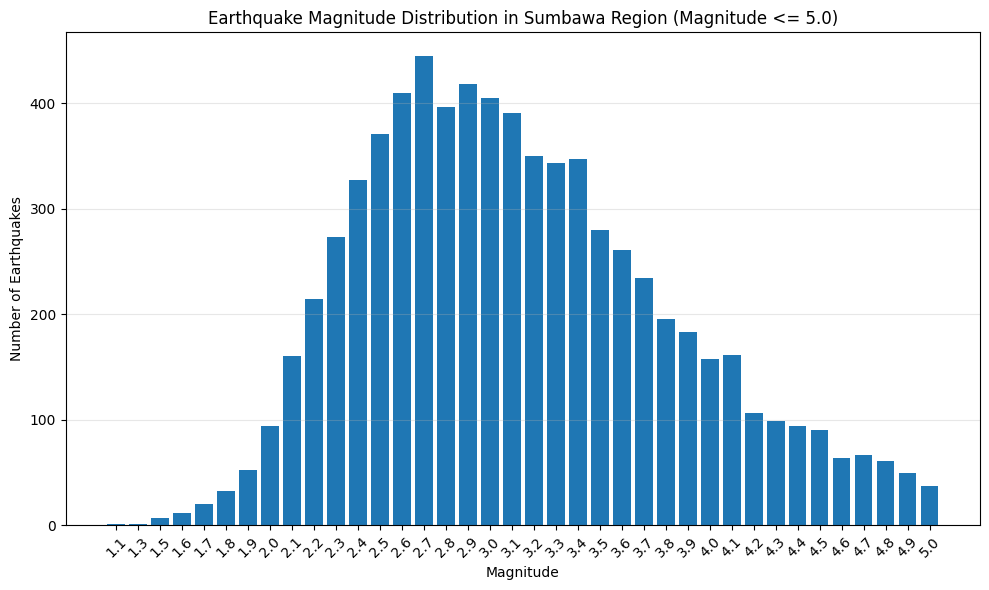

In [12]:
plt.figure(figsize=(10, 6))
plt.bar(visual_1_df["mag"].astype(str), visual_1_df["jumlah_gempa"])
plt.title("Earthquake Magnitude Distribution in Sumbawa Region (Magnitude <= 5.0)")
plt.xlabel("Magnitude")
plt.ylabel("Number of Earthquakes")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# 7. VISUALIZATION 2: MONTHLY SUMBAWA EARTHQUAKE TRENDS (2020-2024)

# Convert common date formats. Add another format here if your CSV differs.
df_dates = df_selected.withColumn(
    "tanggal",
    coalesce(
        to_date(col("tgl"), "yyyy/MM/dd"),
        to_date(col("tgl"), "yyyy-MM-dd"),
        to_date(col("tgl"), "dd/MM/yyyy")
    )
)

print("=== DATE PARSING CHECK ===")
df_dates.select("tgl", "tanggal").show(10, truncate=False)

=== DATE PARSING CHECK ===
+----------+----------+
|tgl       |tanggal   |
+----------+----------+
|2008/11/01|2008-11-01|
|2008/11/01|2008-11-01|
|2008/11/01|2008-11-01|
|2008/11/01|2008-11-01|
|2008/11/01|2008-11-01|
|2008/11/01|2008-11-01|
|2008/11/01|2008-11-01|
|2008/11/01|2008-11-01|
|2008/11/01|2008-11-01|
|2008/11/01|2008-11-01|
+----------+----------+
only showing top 10 rows



In [15]:
print("=== DATA DATE RANGE ===")
df_dates.agg(
    spark_min("tanggal").alias("tanggal_awal"),
    spark_max("tanggal").alias("tanggal_akhir"),
    spark_sum(col("tanggal").isNull().cast("int")).alias("tanggal_gagal_dibaca")
).show()

=== DATA DATE RANGE ===
+------------+-------------+--------------------+
|tanggal_awal|tanggal_akhir|tanggal_gagal_dibaca|
+------------+-------------+--------------------+
|  2008-11-01|   2023-01-26|                   0|
+------------+-------------+--------------------+



In [16]:
df_dates.createOrReplaceTempView("EarthquakesWithDate")

monthly_counts = spark.sql("""
    SELECT TRUNC(tanggal, 'MM') AS bulan, COUNT(*) AS jumlah_gempa
    FROM EarthquakesWithDate
    WHERE remark LIKE '%Sumbawa Region%'
      AND tanggal >= DATE '2020-01-01'
      AND tanggal < DATE '2025-01-01'
    GROUP BY TRUNC(tanggal, 'MM')
""")

In [17]:
# Create all 60 months; months without matching records will be shown as zero.
calendar_df = spark.sql("""
    SELECT EXPLODE(
        SEQUENCE(
            DATE '2020-01-01',
            DATE '2024-12-01',
            INTERVAL 1 MONTH
        )
    ) AS bulan
""")

complete_monthly = (
    calendar_df
    .join(monthly_counts, on="bulan", how="left")
    .fillna({"jumlah_gempa": 0})
    .orderBy("bulan")
)

visual_2_df = complete_monthly.toPandas()
visual_2_df["bulan"] = pd.to_datetime(visual_2_df["bulan"])

print("=== MONTHLY EARTHQUAKE COUNTS ===")
print(visual_2_df.to_string(index=False))
print("Number of months:", len(visual_2_df))
print("Displayed period:", visual_2_df["bulan"].min(), "to", visual_2_df["bulan"].max())

=== MONTHLY EARTHQUAKE COUNTS ===
     bulan  jumlah_gempa
2020-01-01            43
2020-02-01            47
2020-03-01            47
2020-04-01            28
2020-05-01            37
2020-06-01            44
2020-07-01            18
2020-08-01            73
2020-09-01            38
2020-10-01            23
2020-11-01            39
2020-12-01            65
2021-01-01            42
2021-02-01            47
2021-03-01            89
2021-04-01            61
2021-05-01            44
2021-06-01            48
2021-07-01            52
2021-08-01            29
2021-09-01            66
2021-10-01            87
2021-11-01            52
2021-12-01            47
2022-01-01            73
2022-02-01            57
2022-03-01            67
2022-04-01            75
2022-05-01            52
2022-06-01            60
2022-07-01            38
2022-08-01            63
2022-09-01            54
2022-10-01            78
2022-11-01            60
2022-12-01            89
2023-01-01            56
2023-02-01      

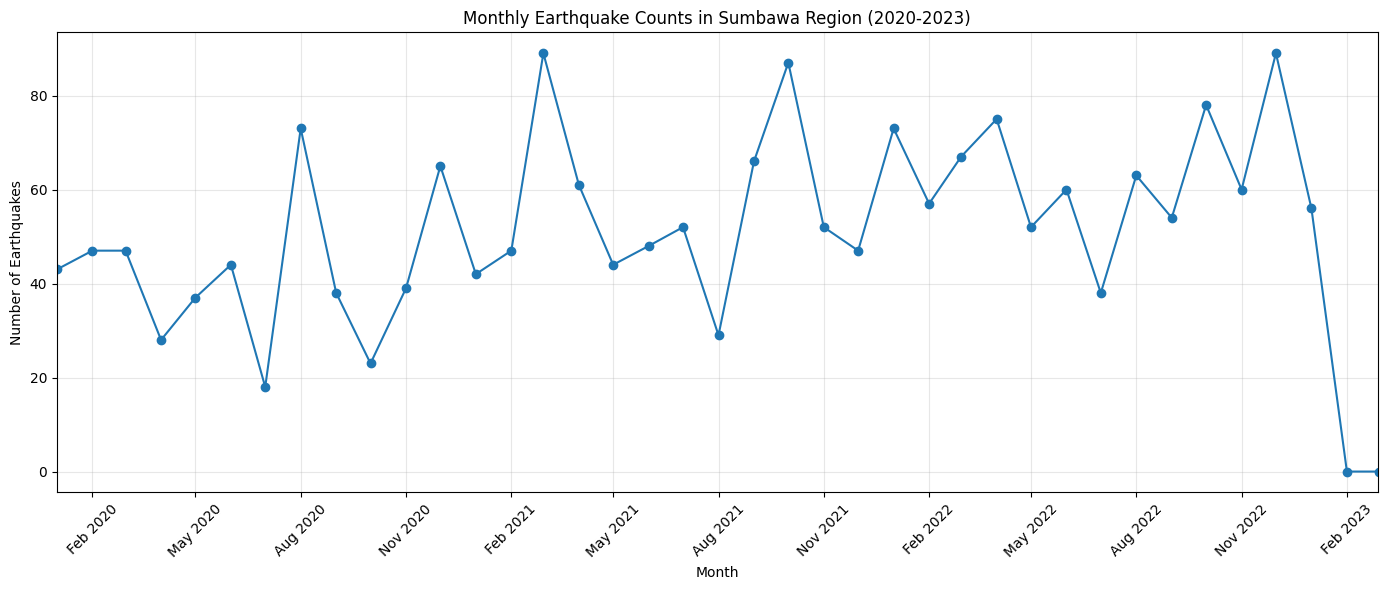

In [24]:
plt.figure(figsize=(14, 6))
plt.plot(visual_2_df["bulan"], visual_2_df["jumlah_gempa"], marker="o")
plt.title("Monthly Earthquake Counts in Sumbawa Region (2020-2023)")
plt.xlabel("Month")
plt.ylabel("Number of Earthquakes")

ax = plt.gca()
ax.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2023-02-28"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# 8. VISUALIZATION 3: EARTHQUAKE MAGNITUDE VS. DEPTH
query_visual_3 = """
SELECT mag, depth
FROM EarthquakesData
WHERE mag IS NOT NULL
  AND depth IS NOT NULL
  AND depth <= 100
"""
visual_3_df = spark.sql(query_visual_3).toPandas()

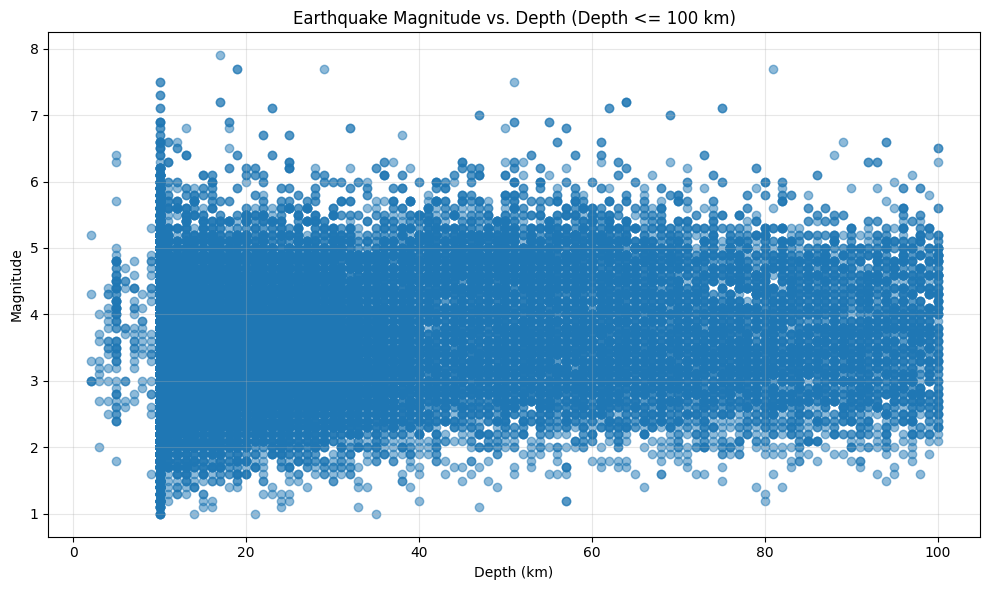

In [20]:
plt.figure(figsize=(10, 6))
plt.scatter(visual_3_df["depth"], visual_3_df["mag"], alpha=0.5)
plt.title("Earthquake Magnitude vs. Depth (Depth <= 100 km)")
plt.xlabel("Depth (km)")
plt.ylabel("Magnitude")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()